# Bulk embedding: similarity between cell lines and a UMAP of the wells

Computes the two tables that show how the cell lines relate to each other in the bulk profiles: a cell line by cell line similarity matrix (for a heat map) and a UMAP of all wells.

**Why:** if the profiles capture the biology of the cell lines, related cell lines (for example of the same cancer group) should look more alike than unrelated ones.

**Input:** `pccma_atlas_pooled_bulk_feature_selected.parquet` (multivariate), made by `4.preprocess_features/3b.pooled_bulk_processing.ipynb`.
It has one row per well and one set of features for all plates, which is what comparing cell lines across plates needs.

**Similarity matrix:** the profile of a cell line at a time point is the mean of its wells on that plate (U2-OS has wells of several conditions on every plate, and all are averaged).
The similarity of two cell lines is the Pearson correlation of their profiles, computed within a time point.

**UMAP:** computed on all wells with the parameters set below and a fixed random seed.
Every cell line is on one layout of three plates, so the positions of cell lines on the map can also reflect the layout and the plate.
The coordinates are saved with the plate, time point, coating, and fixation so that this can be checked.

**Output:** in `results/`
- `bulk_similarity.csv`: one row per pair of cell lines and time point, with the cancer group and tissue site of both.
- `bulk_umap.csv`: one row per well, with its metadata, the UMAP coordinates, and the cell line annotations.

The notebook also plots the UMAP and the similarity matrix; the plots are shown in the notebook and are not saved to disk.

## Import libraries

In [1]:
import itertools
import pathlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
import yaml
from matplotlib.patches import Patch

# UMAP warns that a fixed random seed runs it on one thread, which is what keeps the embedding reproducible
warnings.filterwarnings("ignore", message="n_jobs value")

## Set paths and parameters

In [2]:
metadata_path = pathlib.Path("../cell_lines/pccma_cell_line_metadata.csv")
groups_path = pathlib.Path("../cell_lines/plotting_helpers/cancer_type_categories.yaml")

# pooled bulk profiles: use the local data folder and fall back to the bandicoot mount
pooled_name = "pccma_atlas_pooled_bulk_feature_selected.parquet"
local_dir = pathlib.Path("../4.preprocess_features/data/bulk_profiles")
bandicoot_dir = pathlib.Path("~/mnt/bandicoot/PCCMA_data/Atlas_v2_profiles/bulk_profiles").expanduser()
pooled_path = (local_dir if (local_dir / pooled_name).exists() else bandicoot_dir) / pooled_name

results_dir = pathlib.Path("./results")
results_dir.mkdir(exist_ok=True)

# UMAP settings
umap_parameters = {"n_neighbors": 15, "min_dist": 0.1, "n_components": 2, "metric": "euclidean", "random_state": 0}

## Helper function

In [3]:
def load_cell_line_groups(metadata_path, groups_path):
    """One row per cell line with its cancer type, cancer group and tissue site.

    The cancer groups and tissue sites come from cancer_type_categories.yaml, which lists
    which `cancer_type` values of the metadata belong to each group.
    """
    metadata = pd.read_csv(metadata_path).drop_duplicates("cell_line")  # U2-OS has one row per plate condition
    categories = yaml.safe_load(open(groups_path))
    groups = pd.DataFrame(
        [
            (cancer_type, group["name"], site["name"])
            for site in categories["sites"]
            for group in site["groups"]
            for cancer_type in group["cancer_types"]
        ],
        columns=["cancer_type", "cancer_group", "tissue_site"],
    )
    return metadata[["cell_line", "cancer_type", "origin"]].merge(groups, on="cancer_type", how="left")

## Load the pooled profiles and the cell line annotations

In [4]:
pooled_df = pd.read_parquet(pooled_path)
metadata_cols = [col for col in pooled_df.columns if col.startswith("Metadata_")]
features = [col for col in pooled_df.columns if col not in metadata_cols]

# the pooled profiles name the cell line Metadata_cell_line, as the metadata does in cell_line
cell_line_groups = load_cell_line_groups(metadata_path, groups_path)
pooled_df = pooled_df.merge(cell_line_groups, left_on="Metadata_cell_line", right_on="cell_line", how="left").drop(columns="cell_line")
assert pooled_df["cancer_group"].notna().all(), "a cell line has no cancer group"

print(f"{pooled_path}")
print(f"{len(pooled_df)} wells, {pooled_df['Metadata_cell_line'].nunique()} cell lines, {pooled_df['Metadata_Plate'].nunique()} plates, {len(features)} features")

/Users/waygr/mnt/bandicoot/PCCMA_data/Atlas_v2_profiles/bulk_profiles/pccma_atlas_pooled_bulk_feature_selected.parquet
712 wells, 54 cell lines, 9 plates, 827 features


## Similarity between cell lines

Mean profile of each cell line on each plate, then the Pearson correlation between cell lines at the same time point.

In [5]:
cell_line_profiles = pooled_df.groupby(["Metadata_time_point", "Metadata_cell_line"])[features].mean()

similarity_rows = []
for time_point, profiles in cell_line_profiles.groupby(level=0):
    profiles = profiles.droplevel(0)
    correlation = np.corrcoef(profiles.to_numpy())
    for (i, line_a), (j, line_b) in itertools.product(enumerate(profiles.index), repeat=2):
        similarity_rows.append({"time_point": time_point, "cell_line_a": line_a, "cell_line_b": line_b, "pearson": correlation[i, j]})

similarity_df = pd.DataFrame(similarity_rows)
for suffix in ["a", "b"]:
    similarity_df = similarity_df.merge(
        cell_line_groups[["cell_line", "cancer_group", "tissue_site"]].rename(
            columns={"cell_line": f"cell_line_{suffix}", "cancer_group": f"cancer_group_{suffix}", "tissue_site": f"tissue_site_{suffix}"}
        ),
        on=f"cell_line_{suffix}",
        how="left",
    )
similarity_df.to_csv(results_dir / "bulk_similarity.csv", index=False)

# between different cell lines, is the similarity higher within a cancer group than across groups?
different = similarity_df[similarity_df["cell_line_a"] != similarity_df["cell_line_b"]]
same_group = different["cancer_group_a"] == different["cancer_group_b"]
print("Median Pearson correlation between different cell lines, by time point:")
print(pd.DataFrame({
    "same cancer group": different[same_group].groupby("time_point")["pearson"].median(),
    "different cancer group": different[~same_group].groupby("time_point")["pearson"].median(),
}).round(2).to_string())

Median Pearson correlation between different cell lines, by time point:
            same cancer group  different cancer group
time_point                                           
24                       0.10                    0.00
48                       0.11                    0.01
72                       0.10                    0.08


## UMAP of the wells

In [6]:
embedding = umap.UMAP(**umap_parameters).fit_transform(pooled_df[features].to_numpy())

umap_df = pooled_df[metadata_cols + ["cancer_type", "cancer_group", "tissue_site", "origin"]].copy()
umap_df["umap_1"], umap_df["umap_2"] = embedding[:, 0], embedding[:, 1]
umap_df.to_csv(results_dir / "bulk_umap.csv", index=False)
print(f"UMAP of {len(umap_df)} wells saved")

UMAP of 712 wells saved


## The embedding at a glance

The UMAP of the wells colored by tissue site, and colored by plate (to see whether the plate or layout shapes the map), and the similarity matrix of the cell lines at 24 h.
The plots are displayed here and not saved to disk.

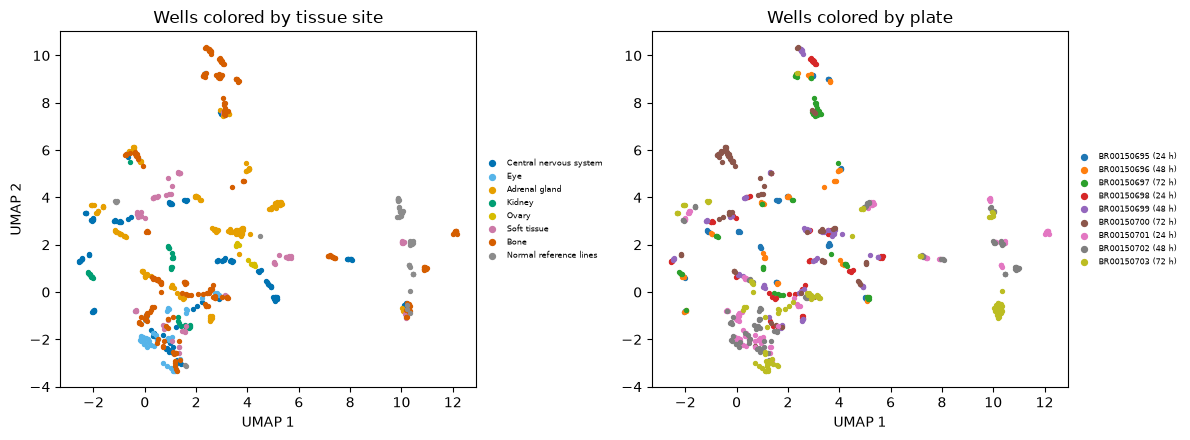

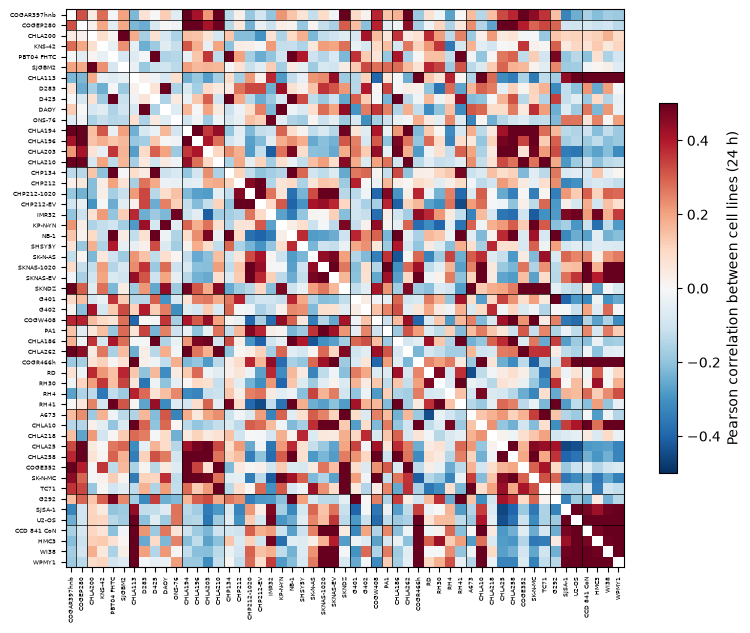

In [7]:
# tissue site colors, the same as `site_colors` in themes.R (in the order of the body, head to toe)
site_colors = {
    "Central nervous system": "#0072B2",
    "Eye": "#56B4E9",
    "Adrenal gland": "#E69F00",
    "Kidney": "#009E73",
    "Ovary": "#D6BC00",
    "Soft tissue": "#CC79A7",
    "Bone": "#D55E00",
    "Normal reference lines": "#8C8C8C",
}
site_rank = {site: rank for rank, site in enumerate(site_colors)}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for site, color in site_colors.items():
    wells = umap_df[umap_df["tissue_site"] == site]
    axes[0].scatter(wells["umap_1"], wells["umap_2"], s=8, color=color, label=site)
for plate, wells in umap_df.groupby("Metadata_Plate"):
    axes[1].scatter(wells["umap_1"], wells["umap_2"], s=8, label=f"{plate} ({wells['Metadata_time_point'].iloc[0]} h)")
axes[0].set(title="Wells colored by tissue site", xlabel="UMAP 1", ylabel="UMAP 2")
axes[1].set(title="Wells colored by plate", xlabel="UMAP 1")
for ax in axes:
    ax.legend(fontsize=6, frameon=False, markerscale=1.5, loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
plt.show()

# similarity matrix at 24 h, cell lines ordered by tissue site and cancer group
at_24 = similarity_df[similarity_df["time_point"] == 24]
lines = (
    at_24[["cell_line_a", "cancer_group_a", "tissue_site_a"]].drop_duplicates()
    .assign(site_rank=lambda df: df["tissue_site_a"].map(site_rank))
    .sort_values(["site_rank", "cancer_group_a", "cell_line_a"])
)
matrix = at_24.pivot(index="cell_line_a", columns="cell_line_b", values="pearson").loc[lines["cell_line_a"], lines["cell_line_a"]]
matrix = matrix.mask(np.eye(len(matrix), dtype=bool))  # the diagonal (1.0) would hide the rest of the scale

fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(matrix, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
ax.set_xticks(range(len(matrix)), matrix.columns, rotation=90, fontsize=4.5)
ax.set_yticks(range(len(matrix)), matrix.index, fontsize=4.5)
groups = lines["cancer_group_a"].to_numpy()
for edge in np.flatnonzero(groups[1:] != groups[:-1]) + 0.5:  # lines between cancer groups
    ax.axhline(edge, color="black", lw=0.5)
    ax.axvline(edge, color="black", lw=0.5)
fig.colorbar(image, ax=ax, shrink=0.6, label="Pearson correlation between cell lines (24 h)")
plt.show()